## Notebook to create a protoplanetary disk

### Initial conditions

In [8]:
import numpy
from amuse.units import units, constants, nbody_system
from amuse.ext.orbital_elements import generate_binaries
from amuse.lab import Particles

In [24]:
# Generating the binary system 

M_A = 1.0788 | units.Msun
M_B = 0.9092 | units.Msun
a = 23.299 | units.au
e = 0.51947
i = 79.243 | units.deg # how it is viewed from earth, unimportant until placing a disk
long_asc_node = 205.073 | units.deg # defines how orbital plane is rotated along LoS, also unimportant
arg_per = 231.519 | units.deg # defines where periapsis lies in orbital plane, unimportant
true_an = 180 | units.deg # stars start at apastron, i.e. furthest apart
primaries, secondaries = generate_binaries(M_A, M_B, a, e, true_anomaly=true_an, G=constants.G)

alpha_cen_A = primaries[0]
alpha_cen_B = secondaries[0]

alpha_cen_A.name = "Alpha_Centauri_A"
alpha_cen_B.name = "Alpha_Centauri_B"

system = Particles()
system.add_particle(alpha_cen_A)
system.add_particle(alpha_cen_B)
system.move_to_center()

print(system)
print(alpha_cen_A.x)

                 key         mass         name           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
 3853855456798605754    1.079e+00  Alpha_Centauri_A    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
13412332459039679284    9.092e-01  Alpha_Centauri_B   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
16.1909547219 149597870691.0 * m


In [10]:
# Candidate planet is a gas giant orbiting Alpha Centauri A. We can start with a fully-formed Saturn mass planet and test orbital stability. 
# After orbital stability is established (hopefully): start with a core of 10-20 Mearth and simulate core accretion of gas to form a gas giant

# First, explore orbital stability of candidate gas giant 

M_embryo = 0.0123 | units.Mearth
a_planet = 2 | units.au
e_planet = 0.4 

stars, planets = generate_binaries(M_A, M_embryo, a_planet, e_planet, G=constants.G)
star = stars[0]
planet = planets[0]
planet.position -= star.position # planet position relative to star 
planet.velocity -= star.velocity # planet velocity relative to star

planet.position += system[0].position # absolute position
planet.velocity += system[0].velocity # absolute velocity 

planet.name = "Alpha_Centauri_Ab"

system.add_particle(planet)
system.move_to_center()
print(system)

                 key         mass         name           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
16584635116453559379    1.079e+00  Alpha_Centauri_A    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
13320134037095429104    9.092e-01  Alpha_Centauri_B   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
 7974194981718508449    3.693e-08  Alpha_Centauri_Ab    1.564e-22    9.779e-06    0.000e+00    1.739e+01   -1.983e-15    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========


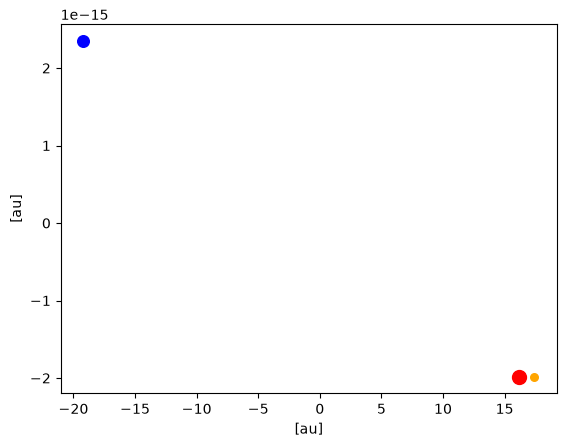

In [11]:
from amuse.plot import scatter

scatter(alpha_cen_A.x.in_(units.au), alpha_cen_A.y.in_(units.au), s=100, c='red')
scatter(alpha_cen_B.x.in_(units.au), alpha_cen_B.y.in_(units.au), s=70, c='blue')
scatter(planet.x.in_(units.au), planet.y.in_(units.au), s=30, c='orange')

In [20]:
from amuse.ext.protodisk import ProtoPlanetaryDisk

M_scale = system.mass.sum()
R_scale = a
converter = nbody_system.nbody_to_si(M_scale, R_scale)
Ndisk = 1000
Rin = 0.2 | units.au
Rout = 3 | units.au
rmin = Rin/R_scale
rmax = Rout/R_scale
Mdisk = 0.001 | units.Msun
disk = ProtoPlanetaryDisk(Ndisk,
                          convert_nbody=converter,
                          radius_min=rmin, # inner radius in units of reference length
                          radius_max=rmax, # outer radius in units of reference length
                          q_out=10.0, # Toomre Q parameter
                          discfraction=Mdisk/M_A).result
disk.name = "disk "
disk.move_to_center()
disk.position += alpha_cen_A.position # absolute coordinates of disk 
disk.velocity += alpha_cen_A.velocity # absolute velocity of disk
masses = Mdisk / float(Ndisk) # mass distributed equally 
disk.mass = masses
rho = 3.0 | (units.g / units.cm**3) # assume density of material
disk.radius = (disk.mass / (4 * rho))**(1./3.) # assign physical radius to each particle using formula
system.add_particles(disk)
system.move_to_center()


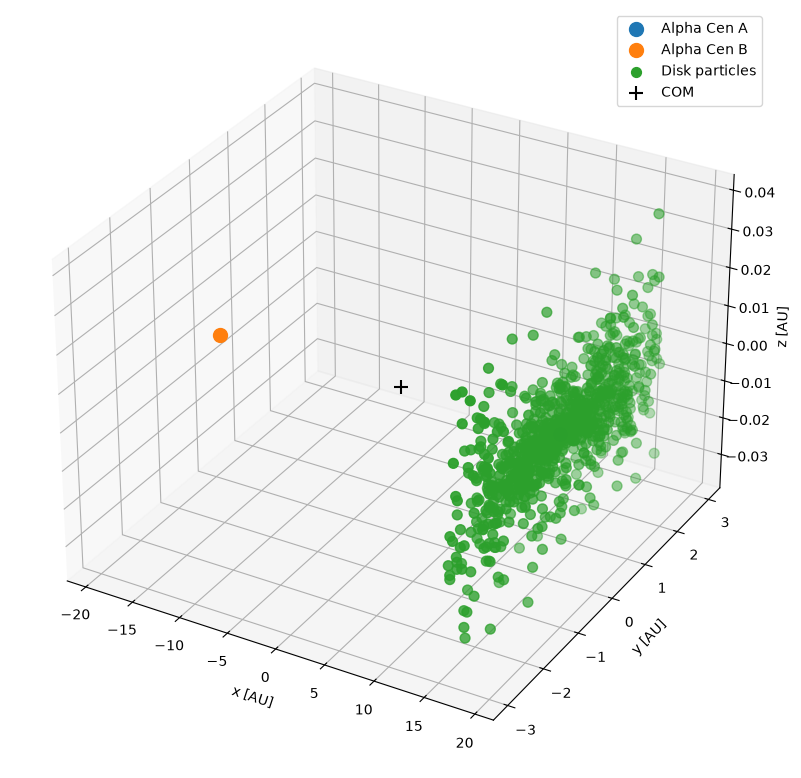

In [27]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(alpha_cen_A.x.value_in(units.au), alpha_cen_A.y.value_in(units.au), alpha_cen_A.z.value_in(units.au), s=100, label="Alpha Cen A")
ax.scatter(alpha_cen_B.x.value_in(units.au), alpha_cen_B.y.value_in(units.au), alpha_cen_B.z.value_in(units.au), s=100, label="Alpha Cen B")

ax.scatter(disk.x.value_in(units.au), disk.y.value_in(units.au), disk.z.value_in(units.au), s=50, marker="o", label="Disk particles")


ax.scatter(0, 0, 0, color="k", marker="+", s=100, label="COM")

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_zlabel("z [AU]")

ax.legend()
plt.tight_layout()